# Лабораторная работа №8: Active learning и human-in-the-loop

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать random, entropy и diversity sampling.
- Провести несколько AL-итераций.
- Построить learning curves при равном бюджете.


## Теоретическая часть

Active learning выбирает следующий batch из pool. Uncertainty ищет неуверенные объекты, diversity покрывает пространство, disagreement использует расхождение моделей. Сравнение корректно только при одинаковом annotation budget.


### Математическая постановка

Entropy sampling: $u(x)=-\sum_c p(c\mid x)\log p(c\mid x)$. Diversity можно реализовать k-center: выбрать объект, максимизирующий расстояние до уже размеченного множества.


### Материалы

- [Active Learning survey](https://arxiv.org/abs/2009.00236)
- [scikit-learn calibration](https://scikit-learn.org/stable/modules/calibration.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Работа выполняется на изображениях рукописных цифр `sklearn.datasets.load_digits`; oracle в этом воспроизводимом эксперименте симулирует человека, открывая истинную метку только после отбора объекта. FAST_DEV_RUN — два раунда проверки кода, полный режим — восемь раундов и повторный random baseline.

In [4]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 45
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

In [11]:
# Библиотеки

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import pairwise_distances
from sklearn.base import clone
from sklearn.metrics import accuracy_score

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Стратифицированный отложенный тест

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отложенный тест» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Разделите изображения цифр по стратифицированному правилу до выбора стратегии.
2. Сохраните и предъявите индексы train/test изображений цифр.

**Результат.** индексы train/test изображений цифр.

**Критерий принятия.** Задание считается принятым, если индексы train/test изображений цифр получены из фактических входов этого этапа и доступны для проверки.

In [6]:
# Загружаем реальные данные
digits = load_digits()
X, y = digits.data, digits.target
indices = np.arange(len(y))

# В FAST_DEV_RUN используем меньшую выборку для проверки кода
if FAST_DEV_RUN:
    _, dev_indices = train_test_split(
        indices,
        train_size=0.2,
        random_state=SEED,
        stratify=y
    )
    indices = np.sort(dev_indices)

# Стратифицированное разделение train/test
train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=y[indices]
)

# Сохраняем индексы исходного датасета
train_indices = np.sort(train_indices)
test_indices = np.sort(test_indices)

save_json("train_test_indices.json", {
    "train_indices": train_indices.tolist(),
    "test_indices": test_indices.tolist()
})

# Предъявляем результат
print(f"Режим FAST_DEV_RUN: {FAST_DEV_RUN}")
print(f"Количество train: {len(train_indices)}")
print(f"Количество test: {len(test_indices)}")
print("Train indices:", train_indices.tolist())
print("Test indices:", test_indices.tolist())

Режим FAST_DEV_RUN: False
Количество train: 1437
Количество test: 360
Train indices: [0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 19, 20, 21, 22, 23, 24, 25, 28, 30, 31, 33, 34, 35, 36, 37, 38, 40, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 65, 66, 68, 69, 70, 71, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 102, 103, 104, 105, 106, 107, 108, 109, 112, 114, 115, 116, 118, 119, 120, 122, 123, 124, 125, 127, 128, 129, 130, 131, 133, 134, 137, 138, 142, 144, 145, 146, 149, 151, 152, 153, 154, 155, 156, 157, 158, 160, 161, 162, 164, 165, 167, 168, 169, 172, 173, 175, 176, 177, 178, 179, 180, 181, 183, 184, 185, 186, 187, 188, 189, 191, 192, 193, 194, 195, 198, 200, 201, 202, 203, 206, 207, 208, 209, 210, 211, 212, 216, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 230, 232, 233, 234, 235, 236, 237, 238, 239, 242, 244, 245, 247, 248, 249, 250, 252, 254, 255, 256, 258, 

### Начальная размеченная выборка

*Вес: 1 балл.*

**Постановка.** Этап «начальная размеченная выборка» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Задайте initial с каждым классом и неразмеченный pool только из train.
2. Сохраните и предъявите непересекающиеся initial и pool.

**Результат.** непересекающиеся initial и pool.

**Критерий принятия.** Задание считается принятым, если непересекающиеся initial и pool получены из фактических входов этого этапа и доступны для проверки.

In [7]:
# Начальная размеченная выборка: одинаковое число объектов каждого класса
N_INITIAL_PER_CLASS = 5

initial_indices, pool_indices = train_test_split(
    train_indices,
    train_size=N_INITIAL_PER_CLASS * len(np.unique(y[train_indices])),
    random_state=SEED,
    stratify=y[train_indices]
)

initial_indices = np.sort(initial_indices)
pool_indices = np.sort(pool_indices)

# Сохраняем индексы и истинные метки initial
save_json("initial_pool_indices.json", {
    "initial_indices": initial_indices.tolist(),
    "initial_labels": y[initial_indices].tolist(),
    "pool_indices": pool_indices.tolist()
})

print(f"Размер initial: {len(initial_indices)}")
print(f"Размер pool: {len(pool_indices)}")
print("Initial indices:", initial_indices.tolist())
print("Pool indices:", pool_indices.tolist())

Размер initial: 50
Размер pool: 1387
Initial indices: [0, 17, 47, 70, 75, 91, 106, 127, 183, 203, 250, 284, 333, 360, 387, 407, 454, 464, 480, 511, 529, 541, 595, 604, 650, 661, 719, 783, 793, 838, 858, 878, 936, 1067, 1101, 1106, 1132, 1136, 1232, 1330, 1345, 1385, 1388, 1483, 1502, 1508, 1529, 1600, 1724, 1758]
Pool indices: [1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 19, 20, 21, 22, 23, 24, 25, 28, 30, 31, 33, 34, 35, 36, 37, 38, 40, 41, 42, 43, 44, 45, 46, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 65, 66, 68, 69, 71, 73, 74, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 87, 88, 89, 90, 92, 93, 94, 95, 96, 97, 98, 99, 102, 103, 104, 105, 107, 108, 109, 112, 114, 115, 116, 118, 119, 120, 122, 123, 124, 125, 128, 129, 130, 131, 133, 134, 137, 138, 142, 144, 145, 146, 149, 151, 152, 153, 154, 155, 156, 157, 158, 160, 161, 162, 164, 165, 167, 168, 169, 172, 173, 175, 176, 177, 178, 179, 180, 181, 184, 185, 186, 187, 188, 189, 191, 192, 193, 194, 195, 198, 200, 201, 202,

### Протокол симулированного разметчика

*Вес: 1 балл.*

**Постановка.** Этап «протокол симулированного разметчика» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните split и документируйте, что oracle открывает метку лишь после выбора.
2. Сохраните и предъявите artifacts/split.json с происхождением меток.

**Результат.** artifacts/split.json с происхождением меток.

**Критерий принятия.** Задание считается принятым, если artifacts/split.json с происхождением меток получены из фактических входов этого этапа и доступны для проверки.

In [8]:
# Протокол симулированного разметчика (oracle)

split_artifact = {
    "dataset": "sklearn.datasets.load_digits",
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "train_indices": train_indices.tolist(),
    "test_indices": test_indices.tolist(),
    "initial_indices": initial_indices.tolist(),
    "pool_indices": pool_indices.tolist(),
    "label_provenance": {
        "source": "digits.target",
        "initial_labels": "Истинные метки доступны для начальной размеченной выборки.",
        "pool_labels": "Oracle открывает истинную метку только после выбора объекта стратегией.",
        "test_labels": "Используются только для итоговой оценки модели, не для обучения или выбора объектов."
    },
    "oracle_protocol": (
        "Стратегия получает изображения из неразмеченного pool, "
        "выбирает индексы объектов, после чего oracle возвращает "
        "их истинные метки из digits.target. До выбора стратегия "
        "не получает метки объектов из pool."
    )
}

save_json("split.json", split_artifact)

print("Артефакт сохранён:", ARTIFACTS / "split.json")
print("Train:", len(train_indices))
print("Test:", len(test_indices))
print("Initial:", len(initial_indices))
print("Pool:", len(pool_indices))
print("Происхождение меток и протокол oracle сохранены.")

Артефакт сохранён: artifacts\split.json
Train: 1437
Test: 360
Initial: 50
Pool: 1387
Происхождение меток и протокол oracle сохранены.


### Три стратегии запроса

*Вес: 1 балл.*

**Постановка.** Этап «три стратегии запроса» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте случайный, энтропийный и k-center выбор; в k-center обновляйте расстояния после каждого объекта.
2. Сохраните и предъявите выбор random, entropy и k-center.

**Результат.** выбор random, entropy и k-center.

**Критерий принятия.** Задание считается принятым, если выбор random, entropy и k-center получены из фактических входов этого этапа и доступны для проверки.

In [10]:
BATCH_SIZE = min(20, len(pool_indices))

# Входные изображения из текущего неразмеченного пула
X_pool = X[pool_indices]
X_initial = X[initial_indices]
y_initial = y[initial_indices]

# Обучаем модель только на начальной размеченной выборке
model = LogisticRegression(max_iter=1000, random_state=SEED)
model.fit(X_initial, y_initial)

# 1. Random sampling
rng = np.random.default_rng(SEED)
random_selected = rng.choice(
    pool_indices, size=BATCH_SIZE, replace=False
)

# 2. Entropy sampling
probabilities = model.predict_proba(X_pool)
eps = 1e-12
entropy = -np.sum(
    probabilities * np.log(np.clip(probabilities, eps, 1.0)),
    axis=1
)
entropy_selected = pool_indices[
    np.argsort(entropy)[-BATCH_SIZE:][::-1]
]

# 3. K-center sampling
# Расстояние между объектами вычисляется в пространстве признаков X
distances = pairwise_distances(X_pool, X_initial)
min_distances = distances.min(axis=1)

kcenter_positions = []
available = np.ones(len(pool_indices), dtype=bool)

for _ in range(BATCH_SIZE):
    # Выбираем объект, максимально удалённый от уже размеченных
    candidate_distances = np.where(available, min_distances, -np.inf)
    chosen = int(np.argmax(candidate_distances))
    kcenter_positions.append(chosen)
    available[chosen] = False

    # Обновляем расстояния с учётом только что выбранного объекта
    new_distances = pairwise_distances(
        X_pool, X_pool[chosen:chosen + 1]
    ).ravel()
    min_distances = np.minimum(min_distances, new_distances)

kcenter_selected = pool_indices[kcenter_positions]

# Сохраняем выбранные индексы
selection_artifact = {
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "batch_size": BATCH_SIZE,
    "random": random_selected.tolist(),
    "entropy": entropy_selected.tolist(),
    "kcenter": kcenter_selected.tolist()
}

save_json("query_selections.json", selection_artifact)

print("Random:", random_selected.tolist())
print("Entropy:", entropy_selected.tolist())
print("K-center:", kcenter_selected.tolist())
print("Артефакт сохранён:", ARTIFACTS / "query_selections.json")

Random: [1652, 1314, 1464, 1086, 988, 1024, 1371, 963, 932, 969, 512, 1032, 1277, 1442, 1229, 1039, 760, 1405, 1408, 781]
Entropy: [899, 1377, 442, 1553, 491, 1338, 459, 958, 355, 423, 1573, 639, 856, 1587, 1585, 1380, 489, 828, 787, 1648]
K-center: [673, 1595, 1024, 1299, 757, 988, 1572, 1264, 1113, 926, 1565, 1070, 1334, 1611, 1576, 1551, 1727, 985, 639, 1671]
Артефакт сохранён: artifacts\query_selections.json


### Итерационное переобучение

*Вес: 1 балл.*

**Постановка.** Этап «итерационное переобучение» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. После каждого запроса дообучайте классификатор на открытых метках и фиксируйте trace.
2. Сохраните и предъявите функция run с фактическими запрошенными метками.

**Результат.** функция run с фактическими запрошенными метками.

**Критерий принятия.** Задание считается принятым, если функция run с фактическими запрошенными метками получены из фактических входов этого этапа и доступны для проверки.

In [12]:
def run(strategy, rounds=None, batch_size=20):
    """
    Итерационное Active Learning:
    strategy(model, X_pool, pool_indices, labeled_indices) -> выбранные индексы.

    Oracle открывает метки только после выбора объектов.
    """
    if rounds is None:
        rounds = 2 if FAST_DEV_RUN else 8

    labeled_indices = initial_indices.tolist()
    remaining_indices = pool_indices.copy().tolist()
    trace = []

    for round_id in range(1, rounds + 1):
        if not remaining_indices:
            break

        # Обучаем классификатор на текущей размеченной выборке
        model = LogisticRegression(max_iter=1000, random_state=SEED)
        model.fit(X[labeled_indices], y[labeled_indices])

        # Стратегия выбирает объекты, не используя их истинные метки
        current_batch_size = min(batch_size, len(remaining_indices))
        selected_indices = strategy(
            model,
            X[remaining_indices],
            np.asarray(remaining_indices),
            np.asarray(labeled_indices)
        )

        selected_indices = np.asarray(selected_indices, dtype=int)
        if len(selected_indices) == 0:
            break

        if len(np.unique(selected_indices)) != len(selected_indices):
            raise ValueError("Стратегия выбрала повторяющиеся индексы.")

        if not set(selected_indices).issubset(set(remaining_indices)):
            raise ValueError("Стратегия вернула индексы вне текущего pool.")

        # Oracle открывает метки только после выбора
        queried_labels = y[selected_indices].tolist()

        labeled_indices.extend(selected_indices.tolist())
        remaining_indices = [
            idx for idx in remaining_indices
            if idx not in set(selected_indices.tolist())
        ]

        # Переобучаем модель на новых открытых метках
        model.fit(X[labeled_indices], y[labeled_indices])

        trace.append({
            "round": round_id,
            "selected_indices": selected_indices.tolist(),
            "queried_labels": queried_labels,
            "n_labeled": len(labeled_indices),
            "test_accuracy": float(
                accuracy_score(y[test_indices], model.predict(X[test_indices]))
            )
        })

    result = {
        "strategy": strategy.__name__,
        "fast_dev_run": FAST_DEV_RUN,
        "trace": trace,
        "final_labeled_indices": labeled_indices,
        "remaining_pool_indices": remaining_indices
    }

    save_json(f"trace_{strategy.__name__}.json", result)
    return result

### Кривые при общем бюджете

*Вес: 1 балл.*

**Постановка.** Этап «кривые при общем бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите точки кривых для одинакового числа запросов и сохраните бюджеты.
2. Сохраните и предъявите artifacts/learning_curves.json.

**Результат.** artifacts/learning_curves.json.

**Критерий принятия.** Задание считается принятым, если artifacts/learning_curves.json получены из фактических входов этого этапа и доступны для проверки.

In [13]:
# Кривые обучения при одинаковом бюджете разметки

def make_strategy(name):
    def strategy(model, X_pool, pool_indices, labeled_indices):
        batch_size = min(BATCH_SIZE, len(pool_indices))

        if name == "random":
            rng = np.random.default_rng(SEED + len(labeled_indices))
            return rng.choice(pool_indices, size=batch_size, replace=False)

        if name == "entropy":
            probabilities = model.predict_proba(X_pool)
            eps = 1e-12
            entropy = -np.sum(
                probabilities * np.log(np.clip(probabilities, eps, 1.0)),
                axis=1
            )
            return pool_indices[np.argsort(entropy)[-batch_size:][::-1]]

        if name == "kcenter":
            distances = pairwise_distances(X_pool, X[labeled_indices])
            min_distances = distances.min(axis=1)
            selected = []
            available = np.ones(len(pool_indices), dtype=bool)

            for _ in range(batch_size):
                candidate_distances = np.where(
                    available, min_distances, -np.inf
                )
                pos = int(np.argmax(candidate_distances))
                selected.append(pool_indices[pos])
                available[pos] = False

                new_distances = pairwise_distances(
                    X_pool, X_pool[pos:pos + 1]
                ).ravel()
                min_distances = np.minimum(min_distances, new_distances)

            return np.asarray(selected)

        raise ValueError(f"Неизвестная стратегия: {name}")

    strategy.__name__ = name
    return strategy


# Одинаковый начальный набор, число раундов и размер batch
rounds = 2 if FAST_DEV_RUN else 8
strategies = ["random", "entropy", "kcenter"]
curves = {}

for name in strategies:
    result = run(make_strategy(name), rounds=rounds, batch_size=BATCH_SIZE)

    curves[name] = [
        {
            "round": 0,
            "budget": len(initial_indices),
            "accuracy": float(
                accuracy_score(
                    y[test_indices],
                    LogisticRegression(max_iter=1000, random_state=SEED)
                    .fit(X[initial_indices], y[initial_indices])
                    .predict(X[test_indices])
                )
            )
        }
    ]

    for point in result["trace"]:
        curves[name].append({
            "round": point["round"],
            "budget": point["n_labeled"],
            "accuracy": point["test_accuracy"]
        })

# Сохраняем реальные точки кривых и бюджеты
learning_curves = {
    "dataset": "sklearn.datasets.load_digits",
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "rounds": rounds,
    "batch_size": BATCH_SIZE,
    "curves": curves
}

save_json("learning_curves.json", learning_curves)

print("Артефакт сохранён:", ARTIFACTS / "learning_curves.json")
for name, points in curves.items():
    print(f"{name}:")
    for point in points:
        print(
            f"  round={point['round']}, "
            f"budget={point['budget']}, "
            f"accuracy={point['accuracy']:.4f}"
        )

Артефакт сохранён: artifacts\learning_curves.json
random:
  round=0, budget=50, accuracy=0.8417
  round=1, budget=70, accuracy=0.8528
  round=2, budget=90, accuracy=0.8750
  round=3, budget=110, accuracy=0.8944
  round=4, budget=130, accuracy=0.8889
  round=5, budget=150, accuracy=0.8972
  round=6, budget=170, accuracy=0.9139
  round=7, budget=190, accuracy=0.9167
  round=8, budget=210, accuracy=0.9111
entropy:
  round=0, budget=50, accuracy=0.8417
  round=1, budget=70, accuracy=0.8833
  round=2, budget=90, accuracy=0.8694
  round=3, budget=110, accuracy=0.8917
  round=4, budget=130, accuracy=0.8806
  round=5, budget=150, accuracy=0.9056
  round=6, budget=170, accuracy=0.9222
  round=7, budget=190, accuracy=0.9389
  round=8, budget=210, accuracy=0.9583
kcenter:
  round=0, budget=50, accuracy=0.8417
  round=1, budget=70, accuracy=0.8944
  round=2, budget=90, accuracy=0.8944
  round=3, budget=110, accuracy=0.9000
  round=4, budget=130, accuracy=0.9194
  round=5, budget=150, accuracy=0.93

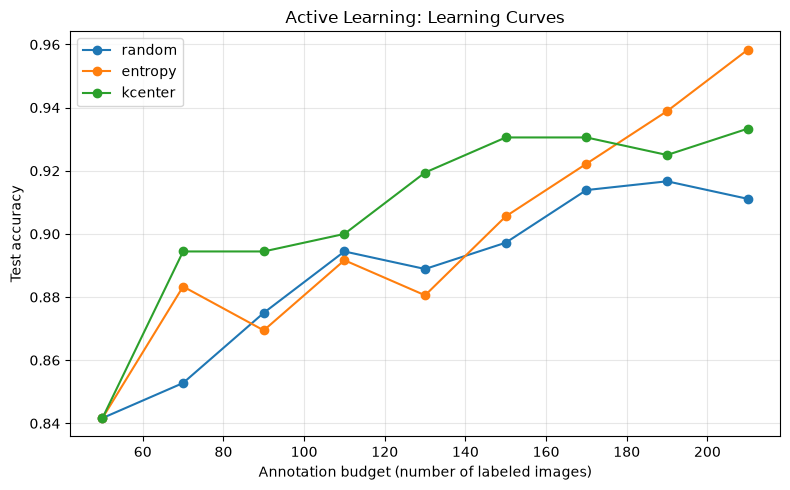

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for strategy_name, points in curves.items():
    budgets = [point["budget"] for point in points]
    accuracies = [point["accuracy"] for point in points]

    plt.plot(
        budgets,
        accuracies,
        marker="o",
        label=strategy_name
    )

plt.xlabel("Annotation budget (number of labeled images)")
plt.ylabel("Test accuracy")
plt.title("Active Learning: Learning Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Сохраняем график в artifacts
plt.savefig(ARTIFACTS / "learning_curves.png", dpi=150)
plt.show()

### Интеграл по бюджету разметки

*Вес: 1 балл.*

**Постановка.** Этап «интеграл по бюджету разметки» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проинтегрируйте кривые accuracy по числу полученных меток.
2. Сохраните и предъявите AUC и конечная accuracy из фактических кривых.

**Результат.** AUC и конечная accuracy из фактических кривых.

**Критерий принятия.** Задание считается принятым, если AUC и конечная accuracy из фактических кривых получены из фактических входов этого этапа и доступны для проверки.

In [15]:
results = {}

for strategy_name, points in learning_curves["curves"].items():
    # Сортируем точки по бюджету разметки
    points = sorted(points, key=lambda point: point["budget"])

    budgets = np.array([point["budget"] for point in points], dtype=float)
    accuracies = np.array([point["accuracy"] for point in points], dtype=float)

    if len(budgets) < 2:
        raise ValueError(
            f"Для стратегии {strategy_name} нужно минимум две точки кривой."
        )
    if len(np.unique(budgets)) != len(budgets):
        raise ValueError(
            f"У стратегии {strategy_name} есть повторяющиеся значения бюджета."
        )

    # Интеграл accuracy по числу размеченных объектов
    auc = float(np.trapezoid(accuracies, x=budgets))
    normalized_auc = float(auc / (budgets[-1] - budgets[0]))
    final_accuracy = float(accuracies[-1])

    results[strategy_name] = {
        "auc": auc,
        "normalized_auc": normalized_auc,
        "final_accuracy": final_accuracy,
        "initial_budget": int(budgets[0]),
        "final_budget": int(budgets[-1]),
        "n_points": len(budgets)
    }

artifact = {
    "source": "learning_curves.json",
    "fast_dev_run": FAST_DEV_RUN,
    "metric": "trapezoidal_integral_of_accuracy_over_labeled_budget",
    "results": results
}

save_json("budget_auc.json", artifact)

print("Результаты интегрирования кривых:")
for name, values in results.items():
    print(
        f"{name:10s} | "
        f"AUC = {values['auc']:.4f} | "
        f"Normalized AUC = {values['normalized_auc']:.4f} | "
        f"Final accuracy = {values['final_accuracy']:.4f}"
    )

print("\nАртефакт сохранён:", ARTIFACTS / "budget_auc.json")


Результаты интегрирования кривых:
random     | AUC = 142.3056 | Normalized AUC = 0.8894 | Final accuracy = 0.9111
entropy    | AUC = 143.8333 | Normalized AUC = 0.8990 | Final accuracy = 0.9583
kcenter    | AUC = 145.6389 | Normalized AUC = 0.9102 | Final accuracy = 0.9333

Артефакт сохранён: artifacts\budget_auc.json


### Повторные случайные запросы

*Вес: 1 балл.*

**Постановка.** Этап «повторные случайные запросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Повторите random с разными генераторами при неизменном train/test.
2. Сохраните и предъявите результаты random при различных seed.

**Результат.** результаты random при различных seed.

**Критерий принятия.** Задание считается принятым, если результаты random при различных seed получены из фактических входов этого этапа и доступны для проверки.

In [18]:
RANDOM_SEEDS = [11, 22, 33, 44, 55]
rounds = 2 if FAST_DEV_RUN else 8

repeated_random_results = []

for random_seed in RANDOM_SEEDS:
    rng = np.random.default_rng(random_seed)

    labeled_indices = initial_indices.tolist()
    remaining_indices = pool_indices.copy().tolist()
    trace = []

    for round_id in range(1, rounds + 1):
        if not remaining_indices:
            break

        batch_size = min(BATCH_SIZE, len(remaining_indices))
        selected = rng.choice(
            remaining_indices, size=batch_size, replace=False
        ).tolist()

        # Oracle открывает метки только после выбора объектов
        labeled_indices.extend(selected)
        selected_set = set(selected)
        remaining_indices = [
            idx for idx in remaining_indices if idx not in selected_set
        ]

        model = LogisticRegression(max_iter=1000, random_state=SEED)
        model.fit(X[labeled_indices], y[labeled_indices])

        accuracy = accuracy_score(
            y[test_indices], model.predict(X[test_indices])
        )

        trace.append({
            "round": round_id,
            "n_labeled": len(labeled_indices),
            "test_accuracy": float(accuracy),
            "selected_indices": selected
        })

    repeated_random_results.append({
        "seed": random_seed,
        "initial_indices": initial_indices.tolist(),
        "trace": trace,
        "final_accuracy": trace[-1]["test_accuracy"] if trace else None
    })

artifact = {
    "dataset": "sklearn.datasets.load_digits",
    "fast_dev_run": FAST_DEV_RUN,
    "train_indices": train_indices.tolist(),
    "test_indices": test_indices.tolist(),
    "random_seeds": RANDOM_SEEDS,
    "results": repeated_random_results
}

save_json("repeated_random.json", artifact)

print("Результаты Random при разных seed:")
for result in repeated_random_results:
    print(
        f"seed={result['seed']:2d} | "
        f"final accuracy={result['final_accuracy']:.4f}"
    )

print("Артефакт сохранён:", ARTIFACTS / "repeated_random.json")


Результаты Random при разных seed:
seed=11 | final accuracy=0.9028
seed=22 | final accuracy=0.9361
seed=33 | final accuracy=0.9361
seed=44 | final accuracy=0.8889
seed=55 | final accuracy=0.9111
Артефакт сохранён: artifacts\repeated_random.json


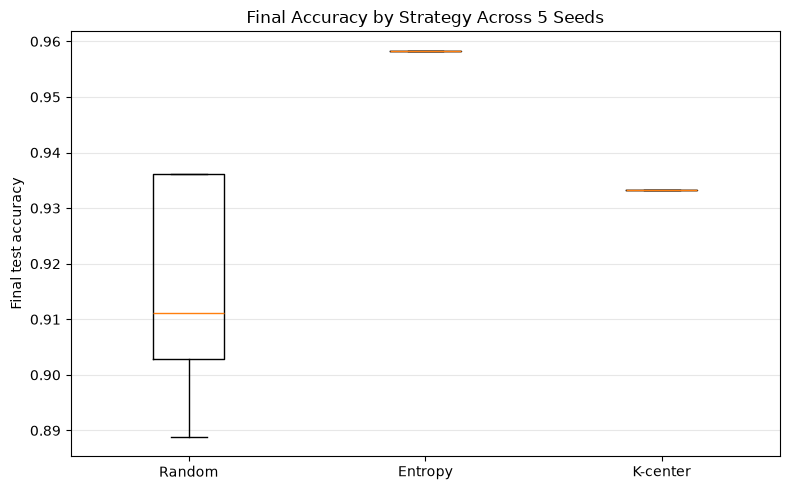

random  : values=[0.9028, 0.9361, 0.9361, 0.8889, 0.9111], mean=0.9150, std=0.0208
entropy : values=[0.9583, 0.9583, 0.9583, 0.9583, 0.9583], mean=0.9583, std=0.0000
kcenter : values=[0.9333, 0.9333, 0.9333, 0.9333, 0.9333], mean=0.9333, std=0.0000
Артефакты сохранены:
artifacts\strategy_seed_boxplots.png
artifacts\strategy_seed_boxplots.json


In [19]:
RANDOM_SEEDS = [11, 22, 33, 44, 55]
ROUNDS = 2 if FAST_DEV_RUN else 8

def run_seeded_strategy(name, random_seed):
    rng = np.random.default_rng(random_seed)
    labeled = initial_indices.copy().tolist()
    remaining = pool_indices.copy().tolist()

    for _ in range(ROUNDS):
        if not remaining:
            break

        model = LogisticRegression(max_iter=1000, random_state=SEED)
        model.fit(X[labeled], y[labeled])
        batch_size = min(BATCH_SIZE, len(remaining))
        pool_X = X[remaining]

        if name == "random":
            selected = rng.choice(remaining, size=batch_size, replace=False)

        elif name == "entropy":
            probs = model.predict_proba(pool_X)
            eps = 1e-12
            ent = -np.sum(probs * np.log(np.clip(probs, eps, 1.0)), axis=1)
            selected = np.asarray(remaining)[
                np.argsort(ent)[-batch_size:]
            ]

        elif name == "kcenter":
            distances = pairwise_distances(pool_X, X[labeled])
            min_dist = distances.min(axis=1)
            available = np.ones(len(remaining), dtype=bool)
            positions = []

            for _ in range(batch_size):
                pos = int(np.argmax(np.where(available, min_dist, -np.inf)))
                positions.append(pos)
                available[pos] = False
                new_dist = pairwise_distances(
                    pool_X, pool_X[pos:pos + 1]
                ).ravel()
                min_dist = np.minimum(min_dist, new_dist)

            selected = np.asarray(remaining)[positions]

        else:
            raise ValueError(f"Неизвестная стратегия: {name}")

        selected = np.asarray(selected, dtype=int)
        labeled.extend(selected.tolist())
        selected_set = set(selected.tolist())
        remaining = [idx for idx in remaining if idx not in selected_set]

    final_model = LogisticRegression(max_iter=1000, random_state=SEED)
    final_model.fit(X[labeled], y[labeled])
    return float(accuracy_score(y[test_indices], final_model.predict(X[test_indices])))

strategies = ["random", "entropy", "kcenter"]
boxplot_results = {
    name: [run_seeded_strategy(name, seed) for seed in RANDOM_SEEDS]
    for name in strategies
}

plt.figure(figsize=(8, 5))
plt.boxplot(
    [boxplot_results[name] for name in strategies],
    tick_labels=["Random", "Entropy", "K-center"]
)
plt.ylabel("Final test accuracy")
plt.title("Final Accuracy by Strategy Across 5 Seeds")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / "strategy_seed_boxplots.png", dpi=150)
plt.show()

save_json("strategy_seed_boxplots.json", {
    "seeds": RANDOM_SEEDS,
    "rounds": ROUNDS,
    "fast_dev_run": FAST_DEV_RUN,
    "final_accuracy": boxplot_results
})

for name, values in boxplot_results.items():
    print(
        f"{name:8s}: "
        f"values={[round(v, 4) for v in values]}, "
        f"mean={np.mean(values):.4f}, std={np.std(values, ddof=1):.4f}"
    )

print("Артефакты сохранены:")
print(ARTIFACTS / "strategy_seed_boxplots.png")
print(ARTIFACTS / "strategy_seed_boxplots.json")


### Разбор ошибок отложенного теста

*Вес: 1 балл.*

**Постановка.** Этап «разбор ошибок отложенного теста» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения и истинные/предсказанные классы ошибочных test-примеров.
2. Сохраните и предъявите artifacts/test_errors.json с неверно распознанными изображениями.

**Результат.** artifacts/test_errors.json с неверно распознанными изображениями.

**Критерий принятия.** Задание считается принятым, если artifacts/test_errors.json с неверно распознанными изображениями получены из фактических входов этого этапа и доступны для проверки.

Стратегия: entropy
Тестовых примеров: 360
Ошибок: 15
Test accuracy: 0.9583
Артефакт сохранён: artifacts\test_errors.json


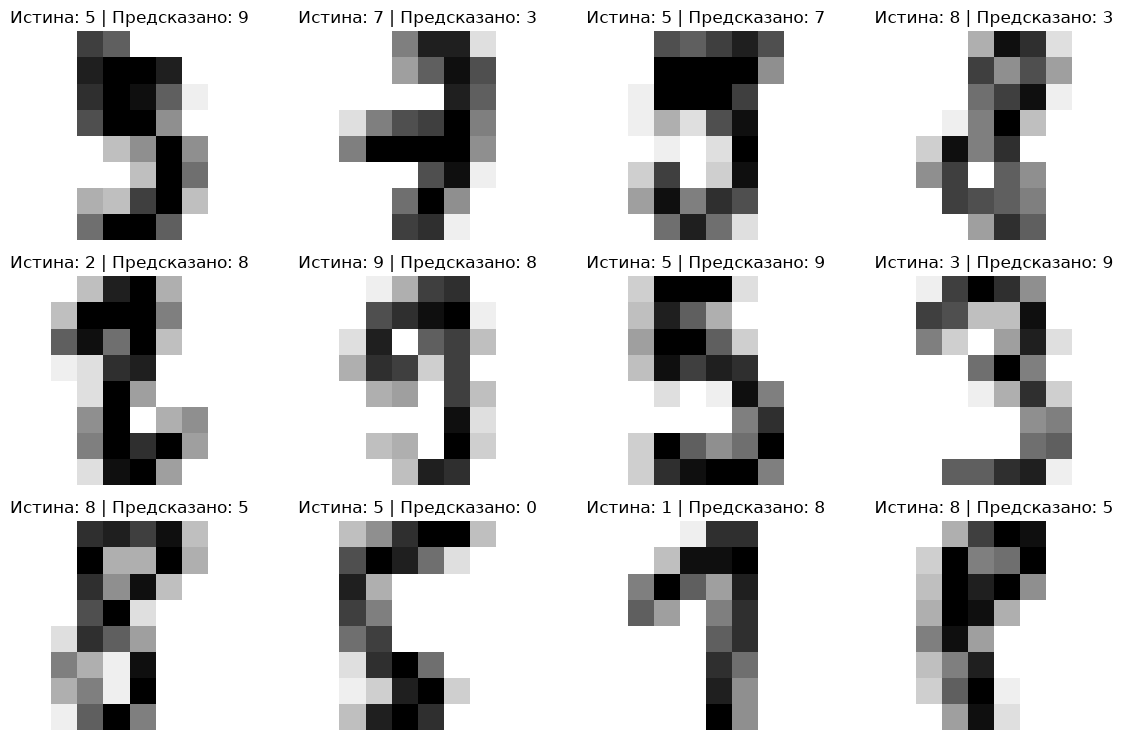

In [23]:
# Ищем стратегию с лучшей конечной accuracy
curves = learning_curves["curves"]
best_strategy = max(
    curves,
    key=lambda name: curves[name][-1]["accuracy"]
)

trace_path = ARTIFACTS / f"trace_{best_strategy}.json"
trace_data = json.loads(trace_path.read_text())
labeled_indices = np.asarray(
    trace_data["final_labeled_indices"], dtype=int
)

model = LogisticRegression(max_iter=1000, random_state=SEED)
model.fit(X[labeled_indices], y[labeled_indices])

y_pred = model.predict(X[test_indices])
y_true = y[test_indices]
wrong_positions = np.flatnonzero(y_pred != y_true)

errors = []
for position in wrong_positions:
    dataset_index = int(test_indices[position])
    errors.append({
        "dataset_index": dataset_index,
        "true_label": int(y_true[position]),
        "predicted_label": int(y_pred[position]),
        "image": digits.images[dataset_index].astype(int).tolist()
    })

artifact = {
    "dataset": "sklearn.datasets.load_digits",
    "seed": SEED,
    "strategy": best_strategy,
    "n_test": int(len(test_indices)),
    "n_errors": int(len(errors)),
    "test_accuracy": float(np.mean(y_pred == y_true)),
    "errors": errors
}

save_json("test_errors.json", artifact)

print(f"Стратегия: {best_strategy}")
print(f"Тестовых примеров: {len(test_indices)}")
print(f"Ошибок: {len(errors)}")
print(f"Test accuracy: {artifact['test_accuracy']:.4f}")
print("Артефакт сохранён:", ARTIFACTS / "test_errors.json")

if errors:
    n_show = min(12, len(errors))
    n_cols = 4
    n_rows = int(np.ceil(n_show / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(12, 2.5 * n_rows)
    )
    axes = np.asarray(axes).reshape(-1)

    for ax, error in zip(axes, errors[:n_show]):
        ax.imshow(error["image"], cmap="gray_r")
        ax.set_title(
            f"Истина: {error['true_label']} | "
            f"Предсказано: {error['predicted_label']}"
        )
        ax.axis("off")

    for ax in axes[n_show:]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(ARTIFACTS / "test_errors.png", dpi=150)
    plt.show()
else:
    print("Ошибок на тестовой выборке нет.")


### Сводка сравнительного эксперимента

*Вес: 1 балл.*

**Постановка.** Этап «сводка сравнительного эксперимента» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сопоставьте AUC и конечную точность по трём стратегиям.
2. Сохраните и предъявите artifacts/comparison.json.

**Результат.** artifacts/comparison.json.

**Критерий принятия.** Задание считается принятым, если artifacts/comparison.json получены из фактических входов этого этапа и доступны для проверки.

In [25]:
import json

# Загружаем реальные результаты предыдущих этапов
curves_path = ARTIFACTS / "learning_curves.json"
auc_path = ARTIFACTS / "budget_auc.json"

if not curves_path.exists() or not auc_path.exists():
    raise FileNotFoundError(
        "Не найдены learning_curves.json или budget_auc.json. "
        "Сначала выполните предыдущие этапы эксперимента."
    )

curves_data = json.loads(curves_path.read_text(encoding="utf-8"))
auc_data = json.loads(auc_path.read_text(encoding="utf-8"))

curves = curves_data["curves"]
auc_results = auc_data["results"]

strategies = ["random", "entropy", "kcenter"]
comparison = {}

for strategy in strategies:
    if strategy not in curves or strategy not in auc_results:
        raise KeyError(f"Нет результатов для стратегии {strategy!r}")

    points = curves[strategy]
    metrics = auc_results[strategy]

    if not points:
        raise ValueError(f"Кривая обучения {strategy!r} пуста")

    curve_final_accuracy = float(points[-1]["accuracy"])
    auc_final_accuracy = float(metrics["final_accuracy"])

    # Проверяем согласованность фактических результатов
    if abs(curve_final_accuracy - auc_final_accuracy) > 1e-9:
        raise ValueError(
            f"Конечная точность {strategy}: "
            f"learning_curves={curve_final_accuracy}, "
            f"budget_auc={auc_final_accuracy}. "
            "Проверьте, что оба артефакта относятся к одному запуску."
        )

    comparison[strategy] = {
        "auc": float(metrics["auc"]),
        "normalized_auc": float(metrics["normalized_auc"]),
        "final_accuracy": auc_final_accuracy,
        "initial_budget": int(metrics["initial_budget"]),
        "final_budget": int(metrics["final_budget"]),
        "n_points": int(metrics["n_points"])
    }

best_auc = max(
    strategies,
    key=lambda s: comparison[s]["auc"]
)
best_normalized_auc = max(
    strategies,
    key=lambda s: comparison[s]["normalized_auc"]
)
best_accuracy = max(
    strategies,
    key=lambda s: comparison[s]["final_accuracy"]
)

artifact = {
    "source_files": [
        "artifacts/learning_curves.json",
        "artifacts/budget_auc.json"
    ],
    "dataset": curves_data.get(
        "dataset", "sklearn.datasets.load_digits"
    ),
    "seed": curves_data.get("seed", SEED),
    "fast_dev_run": curves_data.get("fast_dev_run", FAST_DEV_RUN),
    "metric": auc_data.get("metric"),
    "strategies": comparison,
    "best_by_auc": best_auc,
    "best_by_normalized_auc": best_normalized_auc,
    "best_by_final_accuracy": best_accuracy
}

save_json("comparison.json", artifact)

print("Сравнение стратегий:")
print(f"{'Стратегия':<12} {'AUC':>12} {'Norm. AUC':>12} {'Final accuracy':>16}")
for strategy in strategies:
    m = comparison[strategy]
    print(
        f"{strategy:<12} {m['auc']:>12.6f} "
        f"{m['normalized_auc']:>12.6f} "
        f"{m['final_accuracy']:>16.4f}"
    )

print(f"\nЛучшая по AUC: {best_auc}")
print(f"Лучшая по нормированной AUC: {best_normalized_auc}")
print(f"Лучшая по конечной точности: {best_accuracy}")
print(f"\nАртефакт сохранён: {ARTIFACTS / 'comparison.json'}")
print(json.dumps(artifact, ensure_ascii=False, indent=2))

Сравнение стратегий:
Стратегия             AUC    Norm. AUC   Final accuracy
random         142.305556     0.889410           0.9111
entropy        143.833333     0.898958           0.9583
kcenter        145.638889     0.910243           0.9333

Лучшая по AUC: kcenter
Лучшая по нормированной AUC: kcenter
Лучшая по конечной точности: entropy

Артефакт сохранён: artifacts\comparison.json
{
  "source_files": [
    "artifacts/learning_curves.json",
    "artifacts/budget_auc.json"
  ],
  "dataset": "sklearn.datasets.load_digits",
  "seed": 45,
  "fast_dev_run": false,
  "metric": "trapezoidal_integral_of_accuracy_over_labeled_budget",
  "strategies": {
    "random": {
      "auc": 142.30555555555554,
      "normalized_auc": 0.8894097222222221,
      "final_accuracy": 0.9111111111111111,
      "initial_budget": 50,
      "final_budget": 210,
      "n_points": 9
    },
    "entropy": {
      "auc": 143.83333333333331,
      "normalized_auc": 0.8989583333333332,
      "final_accuracy": 0.95833

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [26]:
# --------------------------------------------------
# 1. Фиксируем протокол исследования
# --------------------------------------------------
BONUS_SEED = 2026
N_INITIAL_PER_CLASS = 5
QUERY_BATCH_SIZE = 20
N_RANDOM_REPEATS = 10
VALIDATION_SIZE = 0.20

rng = np.random.default_rng(BONUS_SEED)
bonus_dir = Path("artifacts")
bonus_dir.mkdir(exist_ok=True)

# Используем только исходную обучающую часть.
# Отложенный test_indices не участвует в эксперименте.
if "train_indices" not in globals():
    raise NameError("Сначала выполните ячейки подготовки train/test.")

base_train_indices = np.asarray(train_indices, dtype=int)

bonus_train_indices, bonus_val_indices = train_test_split(
    base_train_indices,
    test_size=VALIDATION_SIZE,
    random_state=BONUS_SEED,
    stratify=y[base_train_indices]
)

# Создаём отдельный начальный размеченный набор:
# по 5 примеров каждого класса из экспериментальной обучающей части.
initial_parts = []
for cls in np.unique(y[bonus_train_indices]):
    candidates = bonus_train_indices[y[bonus_train_indices] == cls]
    if len(candidates) < N_INITIAL_PER_CLASS:
        raise ValueError(f"Недостаточно примеров класса {cls}")
    initial_parts.extend(
        rng.choice(candidates, N_INITIAL_PER_CLASS, replace=False).tolist()
    )

bonus_initial = np.array(initial_parts, dtype=int)
bonus_pool = np.setdiff1d(bonus_train_indices, bonus_initial)

if len(bonus_pool) < QUERY_BATCH_SIZE:
    raise ValueError("В пуле недостаточно объектов для запроса.")

# --------------------------------------------------
# 2. Обучаем начальную модель и измеряем baseline
# --------------------------------------------------
def fit_model(indices):
    model = LogisticRegression(
        max_iter=2000,
        random_state=BONUS_SEED
    )
    model.fit(X[indices], y[indices])
    return model

def evaluate(model):
    predictions = model.predict(X[bonus_val_indices])
    accuracy = float(np.mean(predictions == y[bonus_val_indices]))
    return accuracy, predictions.astype(int).tolist()

initial_model = fit_model(bonus_initial)
baseline_accuracy, baseline_predictions = evaluate(initial_model)

# --------------------------------------------------
# 3. Entropy: выбираем наиболее неуверенные примеры
# --------------------------------------------------
probabilities = initial_model.predict_proba(X[bonus_pool])
probabilities_safe = np.clip(probabilities, 1e-12, 1.0)

entropies = -np.sum(
    probabilities_safe * np.log(probabilities_safe),
    axis=1
)

entropy_order = np.argsort(-entropies, kind="stable")
entropy_selected = bonus_pool[entropy_order[:QUERY_BATCH_SIZE]]

# Метки выбранных объектов используются только после выбора.
entropy_labeled = np.concatenate([bonus_initial, entropy_selected])
entropy_model = fit_model(entropy_labeled)
entropy_accuracy, entropy_predictions = evaluate(entropy_model)

# --------------------------------------------------
# 4. Random: повторяем выборку 10 раз
# --------------------------------------------------
random_results = []

for repeat in range(N_RANDOM_REPEATS):
    repeat_rng = np.random.default_rng(BONUS_SEED + repeat + 1)
    random_selected = repeat_rng.choice(
        bonus_pool, size=QUERY_BATCH_SIZE, replace=False
    )

    random_labeled = np.concatenate([bonus_initial, random_selected])
    random_model = fit_model(random_labeled)
    accuracy, predictions = evaluate(random_model)

    random_results.append({
        "repeat": repeat + 1,
        "selected_indices": random_selected.astype(int).tolist(),
        "validation_accuracy": accuracy,
        "improvement_over_baseline": accuracy - baseline_accuracy,
        "validation_predictions": predictions
    })

random_accuracies = np.array([
    item["validation_accuracy"] for item in random_results
])
random_improvements = np.array([
    item["improvement_over_baseline"] for item in random_results
])

entropy_improvement = entropy_accuracy - baseline_accuracy
random_mean_accuracy = float(random_accuracies.mean())
random_std_accuracy = float(random_accuracies.std(ddof=1))
random_mean_improvement = float(random_improvements.mean())

# --------------------------------------------------
# 5. Сохраняем данные для проверки воспроизводимости
# --------------------------------------------------
experiment = {
    "dataset": "sklearn.datasets.load_digits",
    "hypothesis": (
        "Высокая энтропия не гарантирует, что разметка выбранных "
        "примеров улучшит качество сильнее случайного выбора."
    ),
    "protocol": {
        "seed": BONUS_SEED,
        "validation_fraction": VALIDATION_SIZE,
        "initial_examples_per_class": N_INITIAL_PER_CLASS,
        "query_batch_size": QUERY_BATCH_SIZE,
        "random_repeats": N_RANDOM_REPEATS,
        "validation_is_disjoint_from_test": True
    },
    "counts": {
        "training_partition": int(len(bonus_train_indices)),
        "validation": int(len(bonus_val_indices)),
        "initial_labeled": int(len(bonus_initial)),
        "pool": int(len(bonus_pool))
    },
    "baseline": {
        "validation_accuracy": baseline_accuracy,
        "validation_predictions": baseline_predictions
    },
    "entropy": {
        "selected_indices": entropy_selected.astype(int).tolist(),
        "selected_entropies": entropies[entropy_order[:QUERY_BATCH_SIZE]].astype(float).tolist(),
        "validation_accuracy": entropy_accuracy,
        "improvement_over_baseline": entropy_improvement,
        "validation_predictions": entropy_predictions
    },
    "random": {
        "mean_validation_accuracy": random_mean_accuracy,
        "std_validation_accuracy": random_std_accuracy,
        "mean_improvement_over_baseline": random_mean_improvement,
        "repeats": random_results
    },
    "comparison": {
        "entropy_minus_random_mean_accuracy": float(
            entropy_accuracy - random_mean_accuracy
        ),
        "entropy_improvement_exceeds_random_mean": bool(
            entropy_improvement > random_mean_improvement
        )
    },
    "validation_true_labels": y[bonus_val_indices].astype(int).tolist(),
    "validation_indices": bonus_val_indices.astype(int).tolist()
}

(bonus_dir / "bonus_experiment.json").write_text(
    json.dumps(experiment, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# --------------------------------------------------
# 6. Формируем отчёт bonus.md по наблюдаемым данным
# --------------------------------------------------
difference = entropy_accuracy - random_mean_accuracy

if difference > 0:
    comparison_text = (
        f"Entropy превысила среднюю точность Random на "
        f"{difference:.4f} ({difference * 100:.2f} п.п.). "
        "В этом запуске гипотеза о том, что Entropy не превосходит "
        "Random, не получила поддержки по конечной точности."
    )
elif difference < 0:
    comparison_text = (
        f"Entropy уступила средней точности Random на "
        f"{abs(difference):.4f} ({abs(difference) * 100:.2f} п.п.). "
        "Это согласуется с гипотезой в данном запуске, "
        "но не доказывает универсальность ограничения."
    )
else:
    comparison_text = (
        "Entropy и средний результат Random совпали по точности. "
        "Это не демонстрирует преимущества Entropy в данном запуске."
    )

report = f"""# Творческое мини-исследование: ограничение Entropy Sampling

## Гипотеза

Высокая энтропия предсказаний не гарантирует, что разметка выбранных
примеров улучшит качество классификатора сильнее, чем случайный выбор
такого же количества объектов.

## Протокол

- Датасет: `sklearn.datasets.load_digits`.
- Случайное состояние: `{BONUS_SEED}`.
- Для исследования использована только исходная обучающая часть данных.
- Из обучающей части заранее выделена стратифицированная валидационная
  выборка размером {len(bonus_val_indices)} объектов.
- Отложенная тестовая выборка не использовалась для выбора гипотезы,
  выбора объектов или оценки результатов этого мини-исследования.
- Начальная обучающая выборка: {len(bonus_initial)} объектов,
  по {N_INITIAL_PER_CLASS} на класс.
- Сравниваются Entropy и Random, каждая стратегия выбирает
  {QUERY_BATCH_SIZE} объектов.
- Random повторён {N_RANDOM_REPEATS} раз с фиксированными seed.
- Качество измеряется accuracy на одной и той же валидационной выборке.
- Воспроизводимые индексы, предсказания и метрики сохранены в
  `artifacts/bonus_experiment.json`.

## Наблюдения

| Метод | Accuracy на валидации | Улучшение относительно baseline |
|---|---:|---:|
| Начальная модель | {baseline_accuracy:.4f} | 0.0000 |
| Entropy | {entropy_accuracy:.4f} | {entropy_improvement:+.4f} |
| Random, среднее | {random_mean_accuracy:.4f} | {random_mean_improvement:+.4f} |

Стандартное отклонение accuracy Random между повторами:
{random_std_accuracy:.4f}.

Разница `Entropy - среднее Random` по accuracy:
{difference:+.4f} ({difference * 100:+.2f} процентного пункта).

{comparison_text}

## Сопоставление с основным экспериментом

В основном эксперименте на отложенной тестовой выборке Budget AUC
составлял 143.833 для Entropy и 142.306 для Random; конечная accuracy
составляла 0.9583 и 0.9111 соответственно.

Это результаты основного эксперимента, приведённые для контекста.
Они не использовались в мини-исследовании для выбора гипотезы или
оценки её результата. Здесь используется отдельный протокол с
валидационной выборкой и новой начальной разметкой, поэтому значения
accuracy напрямую не обязаны совпадать.

## Вывод и ограничения

Результат этого запуска показывает, превзошла ли Entropy средний
результат Random при выбранном бюджете разметки. Он не устанавливает
универсальное превосходство одной стратегии: вывод зависит от
начальной выборки, пула кандидатов, модели и размера бюджета.
Десять повторов Random дают оценку вариативности случайного выбора,
но не заменяют полноценный анализ статистической значимости.

## Артефакты

- `artifacts/bonus_experiment.json` — выбранные индексы, предсказания,
  метрики и параметры протокола.
- `artifacts/bonus.md` — настоящий отчёт.
"""

(bonus_dir / "bonus.md").write_text(report, encoding="utf-8")

print("Baseline accuracy:", round(baseline_accuracy, 4))
print("Entropy accuracy:", round(entropy_accuracy, 4))
print("Random mean accuracy:", round(random_mean_accuracy, 4))
print("Random std accuracy:", round(random_std_accuracy, 4))
print("\nСозданы файлы:")
print(bonus_dir / "bonus_experiment.json")
print(bonus_dir / "bonus.md")
print("\n--- bonus.md ---\n")
print(report)


Baseline accuracy: 0.8333
Entropy accuracy: 0.8229
Random mean accuracy: 0.8632
Random std accuracy: 0.0222

Созданы файлы:
artifacts\bonus_experiment.json
artifacts\bonus.md

--- bonus.md ---

# Творческое мини-исследование: ограничение Entropy Sampling

## Гипотеза

Высокая энтропия предсказаний не гарантирует, что разметка выбранных
примеров улучшит качество классификатора сильнее, чем случайный выбор
такого же количества объектов.

## Протокол

- Датасет: `sklearn.datasets.load_digits`.
- Случайное состояние: `2026`.
- Для исследования использована только исходная обучающая часть данных.
- Из обучающей части заранее выделена стратифицированная валидационная
  выборка размером 288 объектов.
- Отложенная тестовая выборка не использовалась для выбора гипотезы,
  выбора объектов или оценки результатов этого мини-исследования.
- Начальная обучающая выборка: 50 объектов,
  по 5 на класс.
- Сравниваются Entropy и Random, каждая стратегия выбирает
  20 объектов.
- Random повторён 10 раз с 

## Анализ результатов

В основном эксперименте сравнивались три стратегии выбора объектов для разметки: случайный выбор, выбор наиболее неуверенных примеров и выбор наиболее разнообразных примеров. По интегральному показателю лучший результат показала стратегия K-center — 145,64, немного уступившая Entropy по конечной точности. Наибольшая конечная точность была у Entropy — 95,83%, у K-center она составила 93,33%, а у случайного выбора — 91,11%.

В дополнительном исследовании Entropy показала себя хуже случайного выбора. Начальная точность составляла 83,33%, после добавления выбранных Entropy примеров она снизилась до 82,29%, тогда как средняя точность после случайного выбора составила 86,32%. Это согласуется с гипотезой о том, что высокая неуверенность модели не всегда означает полезность примера для обучения. Однако результат относится к одному конкретному протоколу и не доказывает, что Entropy всегда хуже случайного выбора.

У эксперимента есть ограничения: использовался один набор данных, конкретная модель и фиксированный способ разделения выборки. Результаты могут зависеть от начального набора размеченных примеров и случайности выбора. Поэтому выводы нельзя автоматически переносить на другие задачи.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.